<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="Vector Gateway Interface" width="170"></a>

# How many passages should a search return?

A wider result set can recover useful passages, but it also asks a reader to inspect more irrelevant material. We will embed two synthetic help-desk questions and a tiny passage collection with the real **vgi-embed** worker, rank every valid query–passage pair, and measure the tradeoff as we change the number returned.

The eight substantive passages and four relevance judgments below are authored for this demonstration. They are **not a retrieval benchmark**, observed support traffic, or evidence of production quality. Two additional rows deliberately contain missing or blank text. No paid API or external account is involved.

The worker release and numerical runtime are pinned. The BGE model is downloaded on first use and reused from its local cache. See [setup and reproducibility notes](README.md).

## Choose the retrieval count

`TOP_K` is the number of passages returned **per question**, an integer from 1 through 8. Everything else—including model, input text and relevance labels—stays fixed. Edit the value, restart the kernel, and run all. The end experiment changes only this parameter.

In [1]:
TOP_K = 2  # passages per question; accepted range 1..8

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

previous_default, run_at = configure(TOP_K)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = False
%sql connection
connection.execute("CREATE TABLE settings AS SELECT ?::INTEGER AS top_k", [TOP_K])

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-embed-portable-pn2i0qfv/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-embed-portable-pn2i0qfv/pyproject.toml.

## Start the released worker

This literal command fetches the remotely published `v0.5.0` worker and pins the SDK, Arrow, fastembed and ONNX Runtime versions used here. It works from this notebook directory alone; it does not read the repository source or its environment. First use needs network access for packages and model weights. Model loading may take longer than the subsequent SQL.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'embed' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with fastembed==0.9.1 --with onnxruntime==1.31.1 --from git+https://github.com/Query-farm/vgi-embed@v0.5.0 vgi-embed-worker');

,Success


## Make the inputs and evaluation rule inspectable

The two questions concern account recovery and invoice copies. A passage is relevant only when its ID appears in the explicit `(query_id, passage_id)` judgment table. Every other **substantive** passage is judged irrelevant for that question. This closed set is small enough to inspect; it does not imply that unjudged material in a real collection is irrelevant. Missing and whitespace-only text have no usable vector and never become zero-score search candidates.

In [4]:
%%sql
CREATE TABLE passages(passage_id VARCHAR, short_name VARCHAR, body VARCHAR);
INSERT INTO passages VALUES
 ('P01','Password recovery link','Forgot your password? Select the password recovery link on the sign-in page to receive a reset email.'),
 ('P02','Missing reset email','If the password reset email does not arrive, check your spam folder or contact support to recover access to your account.'),
 ('P03','Download an invoice','Open Billing, choose an invoice from your invoice history, and download a PDF copy.'),
 ('P04','Emailed invoices','Your monthly invoice is emailed to the billing contact. Search that inbox for a copy of the invoice.'),
 ('P05','Billing address','To change the address on future bills, update your company details under Billing settings.'),
 ('P06','Office holidays','Our office is closed on public holidays. The help desk reopens on the next business day.'),
 ('P07','Notification settings','Reset your notification preferences from the settings page to restore default email alerts.'),
 ('P08','Storage usage','The storage dashboard shows space used by uploaded files. Delete old files to free up capacity.'),
 ('P09','Missing text',NULL),
 ('P10','Blank text','   ');
CREATE TABLE questions(query_id VARCHAR, topic VARCHAR, question VARCHAR);
INSERT INTO questions VALUES
 ('Q1','Account recovery','I forgot my password. How can I sign in again?'),
 ('Q2','Invoice copies','Where can I find a copy of my invoice?');
CREATE TABLE judgments(query_id VARCHAR, passage_id VARCHAR);
INSERT INTO judgments VALUES ('Q1','P01'),('Q1','P02'),('Q2','P03'),('Q2','P04');
SELECT p.*, string_agg(j.query_id, ', ' ORDER BY j.query_id) AS relevant_for
FROM passages p LEFT JOIN judgments j USING (passage_id)
GROUP BY ALL ORDER BY passage_id;

,passage_id,short_name,body,relevant_for
0,P01,Password recovery link,Forgot your password? Select the password reco...,Q1
1,P02,Missing reset email,"If the password reset email does not arrive, c...",Q1
2,P03,Download an invoice,"Open Billing, choose an invoice from your invo...",Q2
3,P04,Emailed invoices,Your monthly invoice is emailed to the billing...,Q2
4,P05,Billing address,"To change the address on future bills, update ...",None
5,P06,Office holidays,Our office is closed on public holidays. The h...,None
6,P07,Notification settings,Reset your notification preferences from the s...,None
7,P08,Storage usage,The storage dashboard shows space used by uplo...,None
8,P09,Missing text,None,None
9,P10,Blank text,,None


## Embed once, then inspect availability

For BGE retrieval, `embed_query` adds the model’s search instruction to questions; `embed_passage` leaves passages unprefixed. Both calls explicitly select the **same model**. Matching dimensions alone would not make vectors from different models comparable.

The worker generates every vector. Ordinary in-memory tables retain them for all later rankings and charts, so plotting never repeats model inference. The discovery table and diagnostics check the declared width against the actual returned vectors.

In [5]:
%%sql
CREATE TABLE models AS SELECT * FROM embed.supported_models();
CREATE TABLE passage_vectors AS
SELECT *, embed.embed_passage(body, 'BAAI/bge-small-en-v1.5') AS vec FROM passages;
CREATE TABLE query_vectors AS
SELECT *, embed.embed_query(question, 'BAAI/bge-small-en-v1.5') AS vec FROM questions;
SELECT p.passage_id, p.short_name,
       CASE WHEN p.body IS NULL THEN 'missing text'
            WHEN trim(p.body) = '' THEN 'blank text'
            WHEN p.vec IS NULL THEN 'unexpected missing vector'
            ELSE 'available' END AS availability,
       len(p.vec) AS dimensions
FROM passage_vectors p ORDER BY passage_id;

,passage_id,short_name,availability,dimensions
0,P01,Password recovery link,available,384
1,P02,Missing reset email,available,384
2,P03,Download an invoice,available,384
3,P04,Emailed invoices,available,384
4,P05,Billing address,available,384
5,P06,Office holidays,available,384
6,P07,Notification settings,available,384
7,P08,Storage usage,available,384
8,P09,Missing text,missing text,<NA>
9,P10,Blank text,blank text,<NA>


In [6]:
%%sql availability <<
SELECT count(*) AS input_rows, count(vec) AS available,
       count(*) FILTER (WHERE body IS NULL) AS missing_text,
       count(*) FILTER (WHERE body IS NOT NULL AND trim(body) = '') AS blank_text,
       (SELECT dim FROM models WHERE model = 'BAAI/bge-small-en-v1.5') AS model_dimension
FROM passage_vectors;

In [7]:
a = availability.iloc[0]
prose(
    f"**{a.available:.0f} of {a.input_rows:.0f} passages have vectors**, "
    f"each expected to have {a.model_dimension:.0f} dimensions. "
    f"The {a.missing_text:.0f} missing-text and {a.blank_text:.0f} blank-text rows remain unavailable. "
    "We exclude them from both ranking and retrieval-count denominators; they are not numerical zeros."
)

**8 of 10 passages have vectors**, each expected to have 384 dimensions. The 1 missing-text and 1 blank-text rows remain unavailable. We exclude them from both ranking and retrieval-count denominators; they are not numerical zeros.

## Score every candidate and verify the arithmetic

The worker computes cosine similarity, a dimensionless score:

\[
s(q,p)=\frac{\sum_i q_i p_i}{\sqrt{\sum_i q_i^2}\sqrt{\sum_i p_i^2}}.
\]

We rank **all** available passages for each question: this is exhaustive search, with no approximate index. Ties break by passage ID. Cosine similarity is not a probability or a calibrated relevance threshold.

For an independent check, SQL expands the stored `FLOAT` vectors, casts components to `DOUBLE`, and reconstructs the dot product and norms. Agreement with the worker to `1e-6` tests the transported vectors and scoring arithmetic, not whether the model understands the questions. We also check symmetry and self-similarity.

In [8]:
%%sql
CREATE TABLE scores AS
SELECT q.query_id, q.topic, q.question, p.passage_id, p.short_name,
       embed.similarity(q.vec, p.vec) AS score,
       embed.similarity(p.vec, q.vec) AS reverse_score
FROM query_vectors q CROSS JOIN passage_vectors p WHERE p.vec IS NOT NULL;
CREATE TABLE arithmetic AS
SELECT q.query_id, p.passage_id,
       sum(q.vec[i]::DOUBLE * p.vec[i]::DOUBLE) /
       sqrt(sum(q.vec[i]::DOUBLE ^ 2) * sum(p.vec[i]::DOUBLE ^ 2)) AS sql_cosine
FROM query_vectors q CROSS JOIN passage_vectors p,
     UNNEST(range(1, len(q.vec) + 1)) AS indexes(i)
WHERE p.vec IS NOT NULL GROUP BY q.query_id, p.passage_id;
CREATE TABLE self_scores AS
SELECT passage_id, embed.similarity(vec, vec) AS self_score
FROM passage_vectors WHERE vec IS NOT NULL;
CREATE TABLE ranked AS
SELECT s.*, j.passage_id IS NOT NULL AS relevant,
       row_number() OVER (PARTITION BY s.query_id ORDER BY s.score DESC, s.passage_id) AS rank
FROM scores s LEFT JOIN judgments j USING (query_id, passage_id);
SELECT query_id, passage_id, short_name, round(score, 4) AS cosine, relevant, rank
FROM ranked ORDER BY query_id, rank;

,query_id,passage_id,short_name,cosine,relevant,rank
0,Q1,P01,Password recovery link,0.8050,True,1
1,Q1,P02,Missing reset email,0.7281,True,2
2,Q1,P07,Notification settings,0.5578,False,3
3,Q1,P04,Emailed invoices,0.4715,False,4
4,Q1,P06,Office holidays,0.4686,False,5
5,Q1,P05,Billing address,0.4471,False,6
6,Q1,P03,Download an invoice,0.4379,False,7
7,Q1,P08,Storage usage,0.3957,False,8
8,Q2,P04,Emailed invoices,0.8032,True,1
9,Q2,P03,Download an invoice,0.7884,True,2


## How much useful material appears at each cutoff?

Precision at `k` is the number of judged relevant passages among the first `k`, divided by `k`. Recall at `k` divides that same count by all judged relevant passages for that question. With two relevant passages per question, recall moves in steps of one half. A wider result set cannot lower recall on this fixed collection, but precision may rise or fall depending on the newly admitted passage.

The SQL computes every cutoff, then selects the visible `TOP_K`. This keeps the experiment’s scope clear: only the selected prefix changes.

In [9]:
%%sql
CREATE TABLE curves AS
WITH cumulative AS (
 SELECT query_id, topic, rank AS k,
        sum(relevant::INTEGER) OVER (PARTITION BY query_id ORDER BY rank) AS found
 FROM ranked
), totals AS (SELECT query_id, count(*) AS relevant_total FROM judgments GROUP BY query_id)
SELECT *, found::DOUBLE / k AS precision_at_k,
          found::DOUBLE / relevant_total AS recall_at_k
FROM cumulative JOIN totals USING (query_id);
SELECT c.* FROM curves c CROSS JOIN settings s WHERE c.k = s.top_k ORDER BY query_id;

,query_id,topic,k,found,relevant_total,precision_at_k,recall_at_k
0,Q1,Account recovery,2,2.0,2,1.0,1.0
1,Q2,Invoice copies,2,2.0,2,1.0,1.0


In [10]:
%%sql checks <<
SELECT 'declared and actual dimensions agree' AS invariant,
       (SELECT bool_and(len(vec) = (SELECT dim FROM models WHERE model = 'BAAI/bge-small-en-v1.5')) FROM passage_vectors WHERE vec IS NOT NULL)
       AND (SELECT bool_and(len(vec) = 384) FROM query_vectors) AS passed
UNION ALL SELECT 'only missing or blank text lacks a vector',
       (SELECT bool_and((vec IS NULL) = (body IS NULL OR trim(body) = '')) FROM passage_vectors)
UNION ALL SELECT 'each question scores every available passage once',
       (SELECT count(*) = (SELECT count(*) FROM query_vectors) * (SELECT count(vec) FROM passage_vectors)
               AND count(*) = count(DISTINCT (query_id, passage_id)) FROM scores)
UNION ALL SELECT 'finite cosine scores within tolerance of [-1, 1]',
       (SELECT bool_and(score IS NOT NULL AND NOT isnan(score) AND NOT isinf(score) AND abs(score) <= 1 + 1e-6) FROM scores)
UNION ALL SELECT 'worker and SQL cosine agree within 1e-6',
       (SELECT bool_and(abs(score - sql_cosine) < 1e-6) FROM scores JOIN arithmetic USING (query_id, passage_id))
UNION ALL SELECT 'cosine is symmetric and self-similarity is one',
       (SELECT bool_and(abs(score - reverse_score) < 1e-6) FROM scores)
       AND (SELECT bool_and(abs(self_score - 1) < 1e-6) FROM self_scores)
UNION ALL SELECT 'judgments are unique and refer to available pairs',
       (SELECT count(*) = count(DISTINCT (query_id, passage_id)) FROM judgments)
       AND NOT EXISTS (SELECT * FROM judgments ANTI JOIN scores USING (query_id, passage_id))
UNION ALL SELECT 'full collection recovers all judgments',
       (SELECT bool_and(recall_at_k = 1) FROM curves WHERE k = (SELECT count(vec) FROM passage_vectors))
UNION ALL SELECT 'precision and recall are bounded and recall never falls',
       (SELECT bool_and(precision_at_k BETWEEN 0 AND 1 AND recall_at_k BETWEEN 0 AND 1 AND recall_at_k >= previous_recall)
        FROM (SELECT *, lag(recall_at_k, 1, 0) OVER (PARTITION BY query_id ORDER BY k) AS previous_recall FROM curves));

In [11]:
display(checks)
assert checks.passed.fillna(False).all(), "A retrieval invariant failed"
ranking = connection.execute("SELECT * FROM ranked ORDER BY query_id, rank").df()
curve_data = connection.execute("SELECT * FROM curves ORDER BY query_id, k").df()
selected = connection.execute("SELECT * FROM curves WHERE k = ? ORDER BY query_id", [TOP_K]).df()
error = connection.execute(
    "SELECT max(abs(score-sql_cosine)) FROM scores JOIN arithmetic USING(query_id,passage_id)"
).fetchone()[0]
prose(
    f"All **{len(checks)} invariants pass**. "
    f"The largest worker–SQL cosine difference is **{error:.2g}**, below the `1e-6` tolerance. "
    "That numerical agreement is separate from the subjective relevance labels used below."
)

,invariant,passed
0,declared and actual dimensions agree,True
1,only missing or blank text lacks a vector,True
2,each question scores every available passage once,True
3,"finite cosine scores within tolerance of [-1, 1]",True
4,worker and SQL cosine agree within 1e-6,True
5,cosine is symmetric and self-similarity is one,True
6,judgments are unique and refer to available pairs,True
7,full collection recovers all judgments,True
8,precision and recall are bounded and recall ne...,True


All **9 invariants pass**. The largest worker–SQL cosine difference is **1.1e-15**, below the `1e-6` tolerance. That numerical agreement is separate from the subjective relevance labels used below.

## Inspect the ranking before trusting the aggregate

Green markers identify the passages authored as relevant for each question; gray markers identify the other substantive passages. The line separates the selected prefix from the remaining candidates. Scores use the same horizontal scale in both panels, but their absolute values are not calibrated across questions.

findfont: Failed to find font weight semibold for Arial, now using 700.


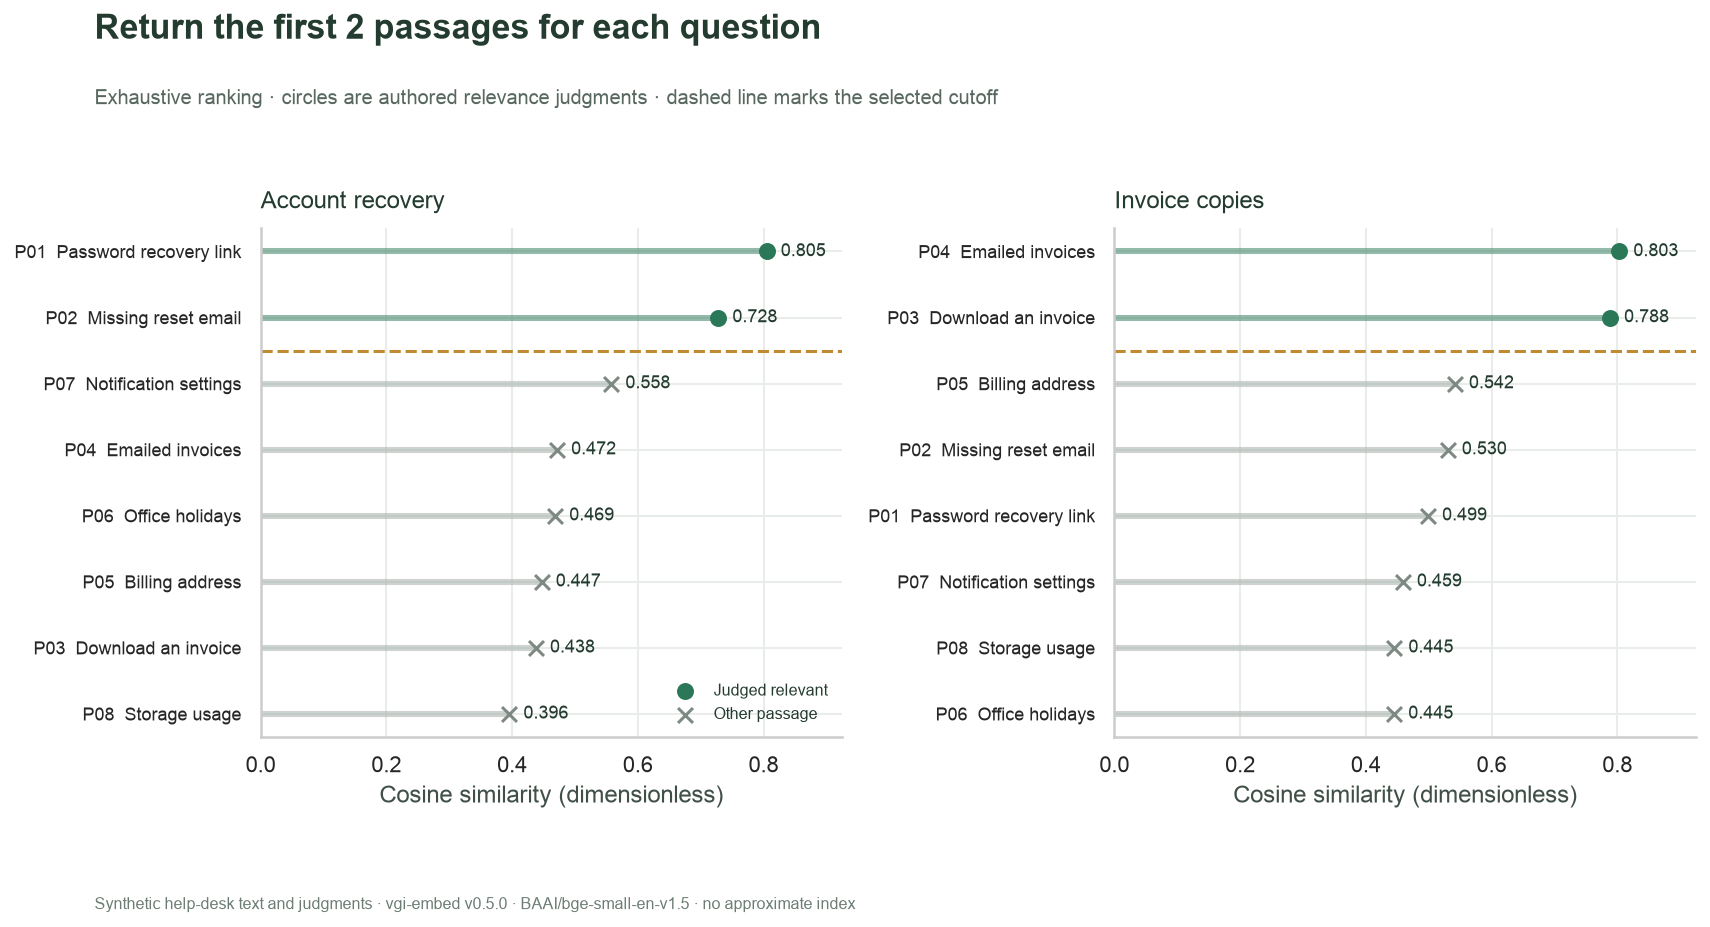

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 6.5), sharex=True)
for ax, (_, part) in zip(axes, ranking.groupby("query_id", sort=True), strict=True):
    y = np.arange(len(part))
    colors = ["#2A7857" if v else "#9EA9A3" for v in part.relevant]
    ax.hlines(y, 0, part.score, color=colors, linewidth=3, alpha=0.5)
    for relevant, marker in [(True, "o"), (False, "x")]:
        mask = part.relevant.to_numpy() == relevant
        ax.scatter(
            part.score.to_numpy()[mask],
            y[mask],
            color="#2A7857" if relevant else "#7D8982",
            marker=marker,
            s=55,
            label="Judged relevant" if relevant else "Other passage",
            zorder=3,
        )
    for pos, row in zip(y, part.itertuples(), strict=True):
        ax.annotate(
            f"{row.score:.3f}",
            (row.score, pos),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
        )
    ax.set_yticks(y, [f"{r.passage_id}  {r.short_name}" for r in part.itertuples()], fontsize=9)
    ax.invert_yaxis()
    if len(part) > TOP_K:
        ax.axhline(TOP_K - 0.5, color="#C08A32", linestyle="--", linewidth=1.5)
    ax.set_title(part.topic.iloc[0], loc="left", fontsize=12, pad=10)
    ax.set_xlabel("Cosine similarity (dimensionless)")
    ax.set_xlim(min(0, ranking.score.min() - 0.05), max(0.9, ranking.score.max() + 0.12))
axes[0].legend(loc="lower right", fontsize=8)
chart(
    fig,
    f"Return the first {TOP_K} passages for each question",
    "Exhaustive ranking · circles are authored relevance judgments · dashed line marks the selected cutoff",
    "Synthetic help-desk text and judgments · vgi-embed v0.5.0 · "
    "BAAI/bge-small-en-v1.5 · no approximate index",
)

In [13]:
lines = []
for row in selected.itertuples():
    ids = ranking[(ranking.query_id == row.query_id) & (ranking["rank"] <= TOP_K)].passage_id.tolist()
    lines.append(
        f"**{row.topic}:** {int(row.found)} of {TOP_K} returned passages are judged relevant "
        f"(precision **{row.precision_at_k:.0%}**); "
        f"{int(row.found)} of {int(row.relevant_total)} relevant passages are recovered "
        f"(recall **{row.recall_at_k:.0%}**). Selected IDs: {', '.join(ids)}."
    )
prose("\n\n".join(lines))

**Account recovery:** 2 of 2 returned passages are judged relevant (precision **100%**); 2 of 2 relevant passages are recovered (recall **100%**). Selected IDs: P01, P02.

**Invoice copies:** 2 of 2 returned passages are judged relevant (precision **100%**); 2 of 2 relevant passages are recovered (recall **100%**). Selected IDs: P04, P03.

## The tradeoff across all retrieval counts

These curves use the same saved scores as the ranking above. Solid green traces recall; dashed amber traces precision. The selected cutoff is highlighted. Returning every candidate guarantees full recall under these complete, authored labels, but includes passages the author judged irrelevant. There is no universal best `k` without a cost for missed information and reader effort.

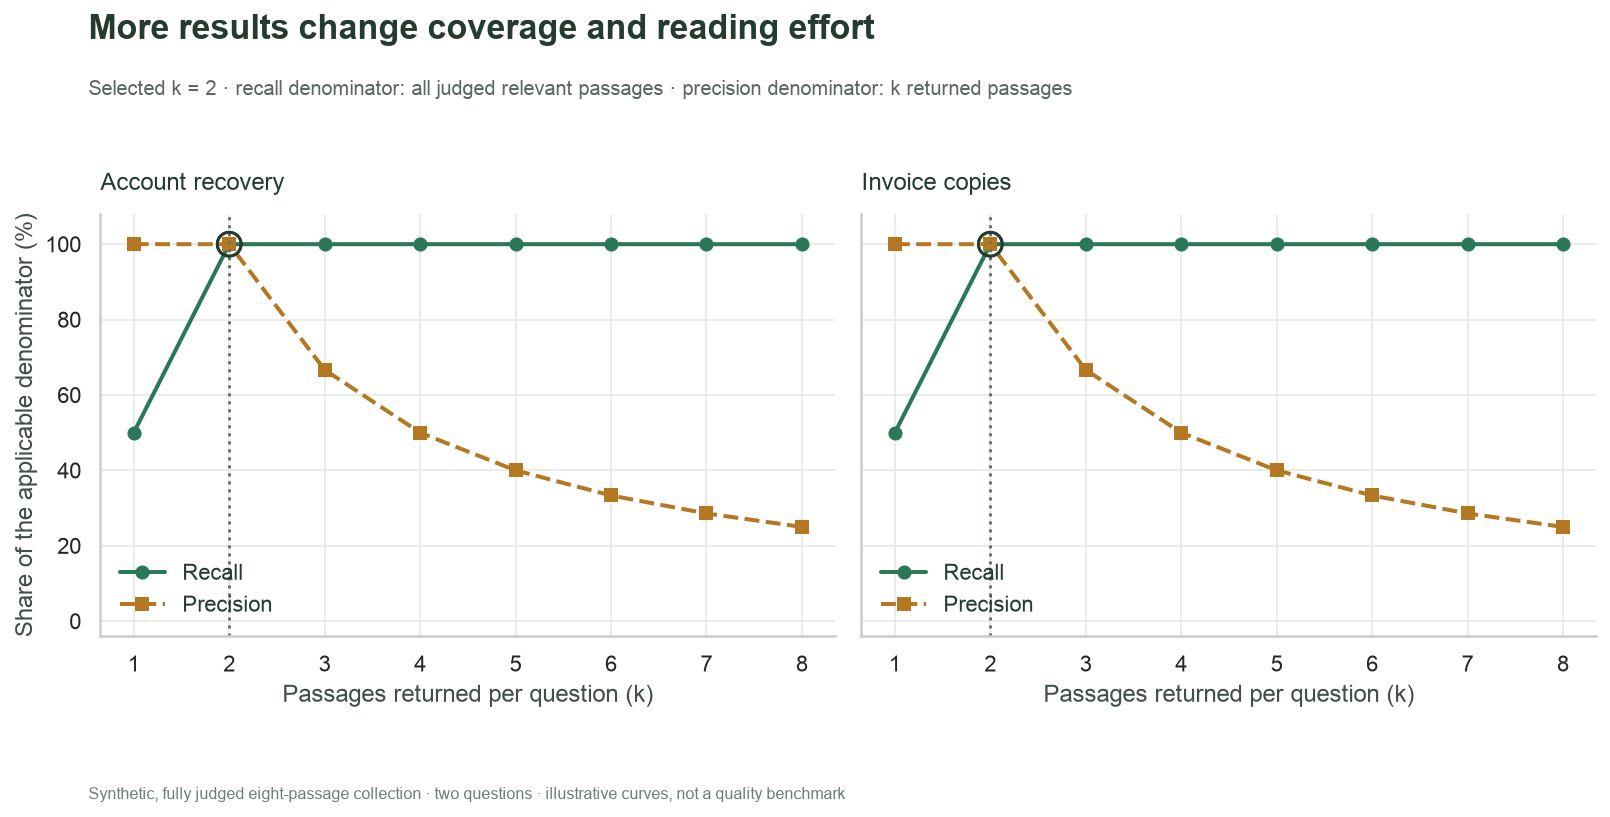

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.7), sharex=True, sharey=True)
for ax, (_, part) in zip(axes, curve_data.groupby("query_id", sort=True), strict=True):
    ax.plot(part.k, part.recall_at_k * 100, "o-", color="#2A7857", label="Recall", linewidth=2)
    ax.plot(part.k, part.precision_at_k * 100, "s--", color="#B47722", label="Precision", linewidth=2)
    chosen = part[part.k == TOP_K].iloc[0]
    ax.axvline(TOP_K, color="#65776C", linestyle=":", linewidth=1.5)
    ax.scatter(
        [TOP_K, TOP_K],
        [chosen.recall_at_k * 100, chosen.precision_at_k * 100],
        s=140,
        facecolors="none",
        edgecolors="#243B2F",
        linewidths=1.4,
        zorder=4,
    )
    ax.set_title(part.topic.iloc[0], loc="left", fontsize=12, pad=12)
    ax.set_xticks(range(1, 9))
    ax.set_ylim(-4, 108)
    ax.set_xlabel("Passages returned per question (k)")
    ax.legend(loc="lower left")
axes[0].set_ylabel("Share of the applicable denominator (%)")
chart(
    fig,
    "More results change coverage and reading effort",
    f"Selected k = {TOP_K} · recall denominator: all judged relevant passages · "
    "precision denominator: k returned passages",
    "Synthetic, fully judged eight-passage collection · two questions · "
    "illustrative curves, not a quality benchmark",
)

## Experiment: widen the result set

Change **`TOP_K` from 2 to 4**, restart, and run all. Predict first: recall cannot fall because the original two results remain included. Precision can fall if the additional passages are irrelevant; it can rise if they are relevant. Compare the selected IDs, counts and highlighted curve positions.

The model, eight substantive passages, two excluded inputs, sixteen scores and complete curves should stay the same, allowing minor platform-level floating-point variation. Only the selected prefix and its interpretation change. Reset `TOP_K = 2` afterward. The README gives a command that saves this experiment separately.

This example establishes arithmetic and selection behavior on authored English text. It does not validate retrieval quality on real support traffic, long documents, another language or an evolving model. Assess those with representative data and independent judgments; a high cosine score alone is not an answer-verification step.

In [15]:
prose(
    f"Run time: `{run_at}`. Haybarn `{haybarn.__version__}`; worker `v0.5.0`; "
    "model `BAAI/bge-small-en-v1.5` (384 dimensions). No API credentials are required. "
    "Model weights are resolved by fastembed under the named model; "
    "package pins do not constitute an immutable model-weight revision."
)
connection.close()
cleanup(previous_default)
plt.close("all")

Run time: `2026-11-14T06:42:35.901069+00:00`. Haybarn `2.0.0rc11`; worker `v0.5.0`; model `BAAI/bge-small-en-v1.5` (384 dimensions). No API credentials are required. Model weights are resolved by fastembed under the named model; package pins do not constitute an immutable model-weight revision.

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>